## Stage 6: Logistic Regression from Scratch
Implementing logistic regression with gradient descent using only NumPy,
and comparing the coefficients with statsmodels.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.discrete.discrete_model import Logit

df = pd.read_csv('olist_model_data.csv')
d = df.dropna(subset=['review_score']).copy()

d['low_score'] = (d['review_score'] <= 2).astype(int)
d['is_late'] = d['is_late'].astype(int)
d['multi_seller'] = (d['n_sellers'] > 1).astype(int)

cols = ['is_late', 'multi_seller', 'log_freight']

Z = (d[cols] - d[cols].mean()) / d[cols].std()
X = np.column_stack([np.ones(len(Z)), Z.values])
y = d['low_score'].values

print('X:', X.shape, ' y:', y.shape)

X: (95824, 4)  y: (95824,)


In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(y, p):
    eps = 1e-12
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

def fit_logistic(X, y, lr=0.5, n_iter=3000):
    beta = np.zeros(X.shape[1])
    losses = []
    for i in range(n_iter):
        p = sigmoid(X @ beta)
        gradient = X.T @ (p - y) / len(y)
        beta = beta - lr * gradient
        losses.append(log_loss(y, p))
    return beta, losses

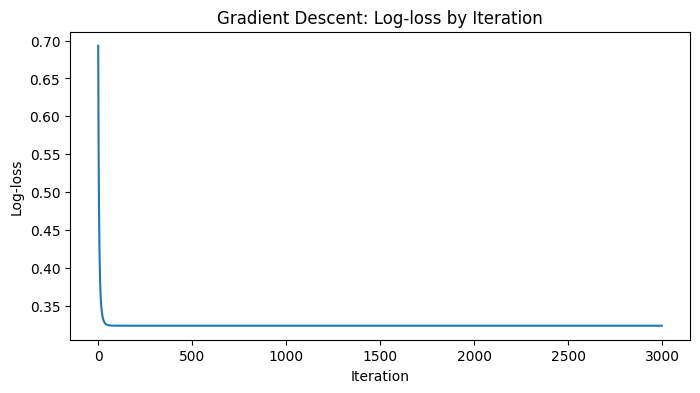

Son itki: 0.32351


In [5]:
beta, losses = fit_logistic(X, y)

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.title('Gradient Descent: Log-loss by Iteration')
plt.xlabel('Iteration')
plt.ylabel('Log-loss')
plt.show()

print('Son itki:', round(losses[-1], 5))

In [6]:
sm_model = Logit(y, X).fit(disp=0)

comparison = pd.DataFrame({
    'from_scratch': beta,
    'statsmodels': sm_model.params
}, index=['intercept'] + cols)

comparison['difference'] = comparison['from_scratch'] - comparison['statsmodels']
comparison.round(4)

,from_scratch,statsmodels,difference
intercept,-2.1458,-2.1458,0.0
is_late,0.7063,0.7063,-0.0
multi_seller,0.2208,0.2208,-0.0
log_freight,0.2245,0.2245,-0.0


### Key findings: Stage 6
- Logistic regression was implemented from scratch with gradient descent (NumPy only).
- Initial loss = log(2) ≈ 0.693 (all coefficients zero → p = 0.5); converged in ~100 iterations.
- Coefficients match statsmodels to 4 decimal places.
- Standardised is_late coefficient (0.71) ÷ SD of is_late (0.25) ≈ 2.8,
  consistent with the unstandardised estimate in Stage 4.
- statsmodels uses Newton–Raphson (second-order) and converges in ~6 iterations;
  gradient descent (first-order) needs more steps but scales to models with many parameters.
  